<a href="https://colab.research.google.com/github/19kaokkk/store/blob/main/ML2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# New Section

In [ ]:

import os
import glob

# Tìm file CSV ở thư mục gốc và thư mục Colab
files = sorted(set(
    glob.glob("/*.csv") + glob.glob("/content/*.csv")
))

print("Số file CSV tìm thấy:", len(files))
print("\nDanh sách file:")

for f in files:
    print("-", f)


Số file CSV tìm thấy: 6

Danh sách file:
- /category_tree_final.csv
- /clean_events_final.csv
- /item_category_history_final.csv
- /item_category_with_parent.csv
- /item_properties_final.csv
- /user_item_event_final.csv


In [ ]:

import pandas as pd
import numpy as np

# Tìm đúng đường dẫn file
candidates = [
    "/content/clean_events_final.csv",
    "/clean_events_final.csv"
]

event_path = next(
    (p for p in candidates if os.path.exists(p)),
    None
)

if event_path is None:
    print("Không tìm thấy clean_events_final.csv.")
    print("Hãy kiểm tra lại kết quả Bước 1.")
else:
    events = pd.read_csv(event_path)

    print("Đường dẫn file:", event_path)
    print("Kích thước dữ liệu:", events.shape)

    print("\nTên các cột:")
    print(events.columns.tolist())

    print("\n5 dòng đầu tiên:")
    display(events.head())

    if "event" in events.columns:
        print("\nPhân bố hành vi:")
        display(events["event"].value_counts(dropna=False))
    else:
        print("\nKhông có cột tên 'event'.")
        print("Cần kiểm tra tên cột thực tế trước khi làm tiếp.")


Đường dẫn file: /clean_events_final.csv
Kích thước dữ liệu: (2755637, 7)

Tên các cột:
['timestamp', 'datetime', 'visitorid', 'session_id', 'event', 'itemid', 'transactionid']

5 dòng đầu tiên:


,timestamp,datetime,visitorid,session_id,event,itemid,transactionid
0,1439487966444,2015-08-13 17:46:06.444,1,1_1,view,72028,NaN
1,1438969904567,2015-08-07 17:51:44.567,2,2_1,view,325215,NaN
2,1438970013790,2015-08-07 17:53:33.790,2,2_1,view,325215,NaN
3,1438970212664,2015-08-07 17:56:52.664,2,2_1,view,259884,NaN
4,1438970468920,2015-08-07 18:01:08.920,2,2_1,view,216305,NaN



Phân bố hành vi:


,count
event,
view,2664215
addtocart,68966
transaction,22456


In [ ]:

print("=" * 55)
print("BƯỚC 3: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU")
print("=" * 55)

# 3.1. Kích thước dữ liệu
print("\n1. Kích thước:", events.shape)

# 3.2. Kiểu dữ liệu từng cột
print("\n2. Kiểu dữ liệu:")
display(events.dtypes.to_frame("data_type"))

# 3.3. Giá trị thiếu
print("\n3. Giá trị thiếu:")
missing_report = pd.DataFrame({
    "missing_count": events.isna().sum(),
    "missing_percent": (events.isna().mean() * 100).round(2)
})
display(missing_report)

# 3.4. Dòng trùng lặp hoàn toàn
print("\n4. Số dòng trùng lặp hoàn toàn:",
      events.duplicated().sum())

# 3.5. Đếm người dùng và sản phẩm nếu có cột tương ứng
for col in ["visitorid", "userid", "user_id"]:
    if col in events.columns:
        print(f"\n5. Số người dùng theo {col}:",
              events[col].nunique())
        break

for col in ["itemid", "item_id", "product_id"]:
    if col in events.columns:
        print(f"6. Số sản phẩm theo {col}:",
              events[col].nunique())
        break

# 3.6. Tìm cột có thể chứa thời gian
time_cols = [
    c for c in events.columns
    if any(word in c.lower()
           for word in ["timestamp", "time", "date"])
]

print("\n7. Các cột có thể chứa thời gian:", time_cols)


BƯỚC 3: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU

1. Kích thước: (2755637, 7)

2. Kiểu dữ liệu:


,data_type
timestamp,int64
datetime,object
visitorid,int64
session_id,object
event,object
itemid,int64
transactionid,float64



3. Giá trị thiếu:


,missing_count,missing_percent
timestamp,0,0.00
datetime,0,0.00
visitorid,0,0.00
session_id,0,0.00
event,0,0.00
itemid,0,0.00
transactionid,2733181,99.19



4. Số dòng trùng lặp hoàn toàn: 0

5. Số người dùng theo visitorid: 1407579
6. Số sản phẩm theo itemid: 235061

7. Các cột có thể chứa thời gian: ['timestamp', 'datetime']


In [ ]:

other_files = [
    "category_tree_final.csv",
    "item_category_history_final.csv",
    "item_category_with_parent.csv",
    "item_properties_final.csv",
    "user_item_event_final.csv"
]

print("BƯỚC 4: KIỂM TRA 5 FILE CÒN LẠI")

for filename in other_files:
    path = next(
        (p for p in [
            "/content/" + filename,
            "/" + filename
        ] if os.path.exists(p)),
        None
    )

    print("\n" + "=" * 55)
    print("FILE:", filename)

    if path is None:
        print("Không tìm thấy file.")
        continue

    # Chỉ đọc một vài dòng để kiểm tra
    sample = pd.read_csv(path, nrows=5)

    print("Đường dẫn:", path)
    print("Các cột:", sample.columns.tolist())
    display(sample.head(3))


BƯỚC 4: KIỂM TRA 5 FILE CÒN LẠI

FILE: category_tree_final.csv
Đường dẫn: /category_tree_final.csv
Các cột: ['categoryid', 'parentid']


,categoryid,parentid
0,0,605.0
1,1,854.0
2,2,312.0



FILE: item_category_history_final.csv
Đường dẫn: /item_category_history_final.csv
Các cột: ['timestamp', 'datetime', 'itemid', 'categoryid']


,timestamp,datetime,itemid,categoryid
0,1431226800000,2015-05-10 03:00:00,0,209
1,1431226800000,2015-05-10 03:00:00,1,1114
2,1431226800000,2015-05-10 03:00:00,2,1305



FILE: item_category_with_parent.csv
Đường dẫn: /item_category_with_parent.csv
Các cột: ['timestamp', 'datetime', 'itemid', 'categoryid', 'parentid']


,timestamp,datetime,itemid,categoryid,parentid
0,1431226800000,2015-05-10 03:00:00,0,209,293.0
1,1431226800000,2015-05-10 03:00:00,1,1114,113.0
2,1431226800000,2015-05-10 03:00:00,2,1305,1214.0



FILE: item_properties_final.csv
Đường dẫn: /item_properties_final.csv
Các cột: ['timestamp', 'datetime', 'itemid', 'property', 'value']


,timestamp,datetime,itemid,property,value
0,1433646000000,2015-06-07 03:00:00,0,1036,1276750
1,1433041200000,2015-05-31 03:00:00,0,1056,n3.168 1144008
2,1433646000000,2015-06-07 03:00:00,0,11,n15360.000 628176 n12288.000



FILE: user_item_event_final.csv
Đường dẫn: /user_item_event_final.csv
Các cột: ['visitorid', 'session_id', 'datetime', 'event', 'itemid', 'transactionid']


,visitorid,session_id,datetime,event,itemid,transactionid
0,1,1_1,2015-08-13 17:46:06.444,view,72028,NaN
1,2,2_1,2015-08-07 17:51:44.567,view,325215,NaN
2,2,2_1,2015-08-07 17:53:33.790,view,325215,NaN


In [ ]:

import pandas as pd
import os

files = {
    "category_tree": "/category_tree_final.csv",
    "item_category_history": "/item_category_history_final.csv",
    "item_category_with_parent": "/item_category_with_parent.csv",
    "item_properties": "/item_properties_final.csv",
    "user_item_event": "/user_item_event_final.csv"
}

for name, path in files.items():
    print("\n" + "=" * 60)
    print("FILE:", name)

    if os.path.exists(path):
        df = pd.read_csv(path)

        print("Số dòng:", len(df))
        print("Số cột:", len(df.columns))
        print("Số dòng trùng lặp:", df.duplicated().sum())
        print("\nSố lượng giá trị thiếu:")
        print(df.isnull().sum())

    else:
        print("Không tìm thấy file:", path)



FILE: category_tree
Số dòng: 1669
Số cột: 2
Số dòng trùng lặp: 0

Số lượng giá trị thiếu:
categoryid     0
parentid      25
dtype: int64

FILE: item_category_history
Số dòng: 788214
Số cột: 4
Số dòng trùng lặp: 0

Số lượng giá trị thiếu:
timestamp     0
datetime      0
itemid        0
categoryid    0
dtype: int64

FILE: item_category_with_parent
Số dòng: 788214
Số cột: 5
Số dòng trùng lặp: 0

Số lượng giá trị thiếu:
timestamp       0
datetime        0
itemid          0
categoryid      0
parentid      218
dtype: int64

FILE: item_properties
Số dòng: 20275902
Số cột: 5
Số dòng trùng lặp: 0

Số lượng giá trị thiếu:
timestamp    0
datetime     0
itemid       0
property     0
value        0
dtype: int64

FILE: user_item_event
Số dòng: 2755637
Số cột: 6
Số dòng trùng lặp: 0

Số lượng giá trị thiếu:
visitorid              0
session_id             0
datetime               0
event                  0
itemid                 0
transactionid    2733181
dtype: int64


In [ ]:

import pandas as pd
import os

# 1. Kiểm tra các loại sự kiện
events = pd.read_csv("/user_item_event_final.csv")

print("===== 1. PHÂN BỐ LOẠI SỰ KIỆN =====")
print(events["event"].value_counts(dropna=False))

print("\n===== 2. TỶ LỆ THIẾU TRANSACTIONID THEO SỰ KIỆN =====")
print(
    events.groupby("event")["transactionid"]
    .agg(
        tong_so_dong="size",
        so_ma_giao_dich="count"
    )
)

# 2. Kiểm tra danh mục không có parentid
category = pd.read_csv("/category_tree_final.csv")

print("\n===== 3. DANH MỤC THIẾU PARENTID =====")
print("Số danh mục thiếu parentid:", category["parentid"].isna().sum())
print(category[category["parentid"].isna()].head(10))

# 3. Kiểm tra parentid thiếu sau khi ghép
history = pd.read_csv("/item_category_with_parent.csv")

print("\n===== 4. KIỂM TRA PARENTID THIẾU =====")
print("Tổng số dòng:", len(history))
print("Số dòng thiếu parentid:", history["parentid"].isna().sum())
print("Số categoryid khác nhau:", history["categoryid"].nunique())

print("\n===== HOÀN TẤT KIỂM TRA =====")


===== 1. PHÂN BỐ LOẠI SỰ KIỆN =====
event
view           2664215
addtocart        68966
transaction      22456
Name: count, dtype: int64

===== 2. TỶ LỆ THIẾU TRANSACTIONID THEO SỰ KIỆN =====
             tong_so_dong  so_ma_giao_dich
event                                     
addtocart           68966                0
transaction         22456            22456
view              2664215                0

===== 3. DANH MỤC THIẾU PARENTID =====
Số danh mục thiếu parentid: 25
     categoryid  parentid
139         140       NaN
227         231       NaN
246         250       NaN
368         378       NaN
385         395       NaN
421         431       NaN
640         653       NaN
646         659       NaN
666         679       NaN
741         755       NaN

===== 4. KIỂM TRA PARENTID THIẾU =====
Tổng số dòng: 788214
Số dòng thiếu parentid: 218
Số categoryid khác nhau: 1242

===== HOÀN TẤT KIỂM TRA =====


In [ ]:

import pandas as pd
import os

# Đọc dữ liệu sự kiện
events = pd.read_csv("/user_item_event_final.csv")

# Chuẩn hóa kiểu dữ liệu và thời gian
events["datetime"] = pd.to_datetime(
    events["datetime"],
    errors="coerce"
)

events["event"] = events["event"].astype("category")

# Tạo cột đánh dấu sự kiện mua hàng
events["is_transaction"] = (
    events["event"].astype(str) == "transaction"
).astype("int8")

# Kiểm tra dữ liệu sau chuẩn hóa
print("===== KIỂM TRA DỮ LIỆU SỰ KIỆN =====")
print("Tổng số dòng:", len(events))
print("Số thời gian không hợp lệ:", events["datetime"].isna().sum())
print("\nSố lượng từng loại sự kiện:")
print(events["event"].value_counts())

print("\nSố sự kiện mua hàng:", events["is_transaction"].sum())

# Lưu file mới, giữ nguyên file gốc
output_path = "/user_item_event_clean.csv"
events.to_csv(output_path, index=False)

print("\nĐã lưu file:", output_path)
print("Dung lượng file (MB):", round(os.path.getsize(output_path) / 1024**2, 2))


===== KIỂM TRA DỮ LIỆU SỰ KIỆN =====
Tổng số dòng: 2755637
Số thời gian không hợp lệ: 0

Số lượng từng loại sự kiện:
event
view           2664215
addtocart        68966
transaction      22456
Name: count, dtype: int64

Số sự kiện mua hàng: 22456

Đã lưu file: /user_item_event_clean.csv
Dung lượng file (MB): 145.8


In [ ]:

import pandas as pd

# Đọc file đã chuẩn hóa
events = pd.read_csv(
    "/user_item_event_clean.csv",
    parse_dates=["datetime"]
)

print("===== 1. KIỂM TRA GIAO DỊCH =====")

transactions = events[
    events["event"] == "transaction"
].copy()

print("Số dòng transaction:", len(transactions))
print(
    "Số transaction ID duy nhất:",
    transactions["transactionid"].nunique()
)
print(
    "Số transaction ID bị lặp:",
    transactions["transactionid"].duplicated().sum()
)

print("\n===== 2. TỔNG HỢP HÀNH VI KHÁCH HÀNG =====")

# Đếm các loại hành vi của mỗi khách hàng
customer_behavior = events.pivot_table(
    index="visitorid",
    columns="event",
    values="itemid",
    aggfunc="count",
    fill_value=0,
    observed=False
).reset_index()

# Đảm bảo đủ các cột hành vi
for col in ["view", "addtocart", "transaction"]:
    if col not in customer_behavior.columns:
        customer_behavior[col] = 0

customer_behavior = customer_behavior.rename(columns={
    "view": "total_views",
    "addtocart": "total_addtocart",
    "transaction": "total_transactions"
})

print("Số khách hàng:", len(customer_behavior))
print("\n5 dòng dữ liệu đầu tiên:")
print(customer_behavior.head())

# Lưu bảng tổng hợp
customer_behavior.to_csv(
    "/customer_behavior_summary.csv",
    index=False
)

print("\nĐã lưu: /customer_behavior_summary.csv")


===== 1. KIỂM TRA GIAO DỊCH =====
Số dòng transaction: 22456
Số transaction ID duy nhất: 17671
Số transaction ID bị lặp: 4785

===== 2. TỔNG HỢP HÀNH VI KHÁCH HÀNG =====
Số khách hàng: 1407579

5 dòng dữ liệu đầu tiên:
event  visitorid  total_addtocart  total_transactions  total_views
0              1                0                   0            1
1              2                0                   0            8
2              3                0                   0            1
3              4                0                   0            1
4              5                0                   0            1

Đã lưu: /customer_behavior_summary.csv


In [ ]:

import pandas as pd

# Đọc dữ liệu sự kiện
events = pd.read_csv("/user_item_event_clean.csv")

# Tổng hợp số lượng khách hàng duy nhất theo hành vi
funnel = events.groupby("event").agg(
    total_events=("visitorid", "size"),
    unique_visitors=("visitorid", "nunique")
).reset_index()

print("===== PHỄU CHUYỂN ĐỔI =====")
print(funnel)

# Lấy số khách hàng duy nhất của từng hành vi
visitor_counts = (
    events.groupby("event")["visitorid"]
    .nunique()
    .to_dict()
)

views = visitor_counts.get("view", 0)
carts = visitor_counts.get("addtocart", 0)
buyers = visitor_counts.get("transaction", 0)

print("\n===== CÁC CHỈ SỐ =====")
print("Khách xem sản phẩm:", views)
print("Khách thêm vào giỏ:", carts)
print("Khách có sự kiện giao dịch:", buyers)

if views > 0:
    print(
        "Tỷ lệ khách thêm giỏ / khách xem:",
        round(carts / views * 100, 2), "%"
    )

if carts > 0:
    print(
        "Tỷ lệ khách có giao dịch / khách thêm giỏ:",
        round(buyers / carts * 100, 2), "%"
    )

if views > 0:
    print(
        "Tỷ lệ khách có giao dịch / khách xem:",
        round(buyers / views * 100, 2), "%"
    )

# Lưu kết quả
funnel.to_csv("/conversion_funnel.csv", index=False)
print("\nĐã lưu: /conversion_funnel.csv")


===== PHỄU CHUYỂN ĐỔI =====
         event  total_events  unique_visitors
0    addtocart         68966            37722
1  transaction         22456            11718
2         view       2664215          1404178

===== CÁC CHỈ SỐ =====
Khách xem sản phẩm: 1404178
Khách thêm vào giỏ: 37722
Khách có sự kiện giao dịch: 11718
Tỷ lệ khách thêm giỏ / khách xem: 2.69 %
Tỷ lệ khách có giao dịch / khách thêm giỏ: 31.06 %
Tỷ lệ khách có giao dịch / khách xem: 0.83 %

Đã lưu: /conversion_funnel.csv


In [ ]:

import pandas as pd

# Đọc dữ liệu sự kiện
events = pd.read_csv(
    "/user_item_event_clean.csv",
    usecols=["visitorid", "event"]
)

# Tạo bảng hành vi theo từng khách hàng
customer_funnel = events.pivot_table(
    index="visitorid",
    columns="event",
    values="visitorid",
    aggfunc="size",
    fill_value=0
)

# Đảm bảo có đủ các cột
for col in ["view", "addtocart", "transaction"]:
    if col not in customer_funnel.columns:
        customer_funnel[col] = 0

# Chuyển số lần thành cờ có/không
customer_funnel["has_view"] = (
    customer_funnel["view"] > 0
)
customer_funnel["has_addtocart"] = (
    customer_funnel["addtocart"] > 0
)
customer_funnel["has_transaction"] = (
    customer_funnel["transaction"] > 0
)

# Kiểm tra giao nhau giữa các nhóm hành vi
print("===== PHÂN TÍCH HÀNH VI KHÁCH HÀNG =====")
print("Tổng khách hàng:", len(customer_funnel))

print(
    "Khách vừa xem vừa thêm giỏ:",
    (
        customer_funnel["has_view"]
        & customer_funnel["has_addtocart"]
    ).sum()
)

print(
    "Khách vừa thêm giỏ vừa giao dịch:",
    (
        customer_funnel["has_addtocart"]
        & customer_funnel["has_transaction"]
    ).sum()
)

print(
    "Khách có đủ cả 3 hành vi:",
    (
        customer_funnel["has_view"]
        & customer_funnel["has_addtocart"]
        & customer_funnel["has_transaction"]
    ).sum()
)

print(
    "Khách có giao dịch nhưng không có sự kiện thêm giỏ:",
    (
        customer_funnel["has_transaction"]
        & ~customer_funnel["has_addtocart"]
    ).sum()
)

# Lưu bảng
customer_funnel.to_csv(
    "/customer_funnel_detail.csv"
)

print("\nĐã lưu: /customer_funnel_detail.csv")


===== PHÂN TÍCH HÀNH VI KHÁCH HÀNG =====
Tổng khách hàng: 1407579
Khách vừa xem vừa thêm giỏ: 34401
Khách vừa thêm giỏ vừa giao dịch: 10575
Khách có đủ cả 3 hành vi: 10227
Khách có giao dịch nhưng không có sự kiện thêm giỏ: 1143

Đã lưu: /customer_funnel_detail.csv


In [ ]:

import pandas as pd

# Đọc các cột cần thiết
events = pd.read_csv(
    "/user_item_event_clean.csv",
    usecols=[
        "visitorid",
        "session_id",
        "datetime",
        "event",
        "itemid",
        "transactionid"
    ],
    parse_dates=["datetime"]
)

# Tổng hợp hành vi theo khách hàng và phiên
session_summary = events.pivot_table(
    index=["visitorid", "session_id"],
    columns="event",
    values="itemid",
    aggfunc="count",
    fill_value=0
).reset_index()

# Đảm bảo có đủ các cột
for col in ["view", "addtocart", "transaction"]:
    if col not in session_summary.columns:
        session_summary[col] = 0

# Đánh dấu hành vi trong phiên
session_summary["has_view"] = (
    session_summary["view"] > 0
).astype(int)

session_summary["has_addtocart"] = (
    session_summary["addtocart"] > 0
).astype(int)

session_summary["has_transaction"] = (
    session_summary["transaction"] > 0
).astype(int)

print("===== PHÂN TÍCH THEO PHIÊN =====")
print("Tổng số phiên:", len(session_summary))

print("\nSố phiên có xem sản phẩm:",
      session_summary["has_view"].sum())

print("Số phiên có thêm giỏ:",
      session_summary["has_addtocart"].sum())

print("Số phiên có giao dịch:",
      session_summary["has_transaction"].sum())

print("\nSố phiên có đủ 3 hành vi:",
      (
          (session_summary["has_view"] == 1)
          & (session_summary["has_addtocart"] == 1)
          & (session_summary["has_transaction"] == 1)
      ).sum())

# Lưu kết quả
session_summary.to_csv(
    "/session_behavior_summary.csv",
    index=False
)

print("\nĐã lưu: /session_behavior_summary.csv")


===== PHÂN TÍCH THEO PHIÊN =====
Tổng số phiên: 1761674

Số phiên có xem sản phẩm: 1755780
Số phiên có thêm giỏ: 43924
Số phiên có giao dịch: 14296

Số phiên có đủ 3 hành vi: 11142

Đã lưu: /session_behavior_summary.csv


In [ ]:

import pandas as pd

# Chỉ đọc các cột cần thiết
events = pd.read_csv(
    "/user_item_event_clean.csv",
    usecols=[
        "visitorid", "session_id",
        "datetime", "event"
    ],
    parse_dates=["datetime"]
)

# Sắp xếp sự kiện theo thời gian trong từng phiên
events = events.sort_values(
    ["visitorid", "session_id", "datetime"]
)

# Lấy thời điểm xuất hiện đầu tiên của mỗi hành vi
first_event = events.pivot_table(
    index=["visitorid", "session_id"],
    columns="event",
    values="datetime",
    aggfunc="min"
).reset_index()

# Kiểm tra đủ các cột
for col in ["view", "addtocart", "transaction"]:
    if col not in first_event.columns:
        first_event[col] = pd.NaT

# Đánh dấu phiên có đúng trình tự thời gian
first_event["view_before_cart"] = (
    first_event["view"].notna()
    & first_event["addtocart"].notna()
    & (first_event["view"] <= first_event["addtocart"])
)

first_event["cart_before_transaction"] = (
    first_event["addtocart"].notna()
    & first_event["transaction"].notna()
    & (first_event["addtocart"] <= first_event["transaction"])
)

first_event["ordered_funnel"] = (
    first_event["view_before_cart"]
    & first_event["cart_before_transaction"]
)

print("===== KIỂM TRA TRÌNH TỰ HÀNH VI =====")
print("Tổng số phiên:", len(first_event))

print(
    "Phiên có xem trước khi thêm giỏ:",
    first_event["view_before_cart"].sum()
)

print(
    "Phiên có thêm giỏ trước giao dịch:",
    first_event["cart_before_transaction"].sum()
)

print(
    "Phiên có đủ trình tự xem → giỏ → giao dịch:",
    first_event["ordered_funnel"].sum()
)

# Lưu bảng kết quả
first_event.to_csv(
    "/session_ordered_funnel.csv",
    index=False
)

print("\nĐã lưu: /session_ordered_funnel.csv")


===== KIỂM TRA TRÌNH TỰ HÀNH VI =====
Tổng số phiên: 1761674
Phiên có xem trước khi thêm giỏ: 35832
Phiên có thêm giỏ trước giao dịch: 11759
Phiên có đủ trình tự xem → giỏ → giao dịch: 10410

Đã lưu: /session_ordered_funnel.csv


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/user_item_event_clean.csv",
    usecols=["visitorid", "session_id", "datetime", "event", "itemid"]
)

df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Thống kê số phiên và thời lượng phiên
session_stats = df.groupby(["visitorid", "session_id"]).agg(
    start_time=("datetime", "min"),
    end_time=("datetime", "max"),
    total_events=("event", "size"),
    has_transaction=("event", lambda x: (x == "transaction").any())
).reset_index()

session_stats["duration_minutes"] = (
    session_stats["end_time"] - session_stats["start_time"]
).dt.total_seconds() / 60

print("Tổng số phiên:", len(session_stats))
print("\nTỷ lệ phiên có giao dịch:")
print(session_stats["has_transaction"].value_counts(normalize=True).round(4))

print("\nThống kê thời lượng phiên (phút):")
print(session_stats["duration_minutes"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9]
).round(2))

print("\nSố phiên có thời lượng từ 5 phút trở lên:",
      (session_stats["duration_minutes"] >= 5).sum())

print("\nSố phiên có giao dịch:")
print(session_stats["has_transaction"].sum())

Tổng số phiên: 1761674

Tỷ lệ phiên có giao dịch:
has_transaction
False    0.9919
True     0.0081
Name: proportion, dtype: float64

Thống kê thời lượng phiên (phút):
count    1761674.00
mean           1.75
std            8.33
min            0.00
25%            0.00
50%            0.00
75%            0.00
90%            3.55
max          728.40
Name: duration_minutes, dtype: float64

Số phiên có thời lượng từ 5 phút trở lên: 146634

Số phiên có giao dịch:
14296


In [ ]:
import pandas as pd
import os

clean_path = "/user_item_event_clean.csv"
original_path = "/user_item_event_final.csv"

# Kiểm tra và tự động chuẩn hóa lại nếu file clean bị mất
if not os.path.exists(clean_path):
    print(f"Không tìm thấy {clean_path}. Đang tiến hành chuẩn hóa từ file gốc {original_path}...")
    if os.path.exists(original_path):
        events = pd.read_csv(original_path)
        events["datetime"] = pd.to_datetime(events["datetime"], errors="coerce")
        events["event"] = events["event"].astype("category")
        events["is_transaction"] = (events["event"].astype(str) == "transaction").astype("int8")
        events.to_csv(clean_path, index=False)
        print("Đã tái tạo thành công file clean.")
    else:
        raise FileNotFoundError(f"Không tìm thấy cả {clean_path} lẫn {original_path}. Vui lòng tải lại dữ liệu.")

df = pd.read_csv(
    clean_path,
    usecols=["visitorid", "session_id", "datetime", "event", "itemid"]
)

df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Tìm thời điểm giao dịch đầu tiên trong mỗi phiên
transaction_times = (
    df[df["event"] == "transaction"]
    .groupby(["visitorid", "session_id"])["datetime"]
    .min()
    .rename("first_transaction_time")
)

# Gắn thời điểm giao dịch vào các sự kiện tương ứng
df = df.join(
    transaction_times,
    on=["visitorid", "session_id"]
)

# Chỉ xét phiên có giao dịch và các sự kiện không phải transaction
interactions = df[
    df["first_transaction_time"].notna()
    & (df["event"] != "transaction")
].copy()

# Kiểm tra thời điểm tương tác so với giao dịch đầu tiên
interactions["timing"] = "same_time"
interactions.loc[
    interactions["datetime"] < interactions["first_transaction_time"],
    "timing"
] = "before_transaction"

interactions.loc[
    interactions["datetime"] > interactions["first_transaction_time"],
    "timing"
] = "after_transaction"

print("Số sự kiện tương tác trong các phiên có giao dịch:")
print(interactions["event"].value_counts())

print("\nThời điểm tương tác so với giao dịch đầu tiên:")
print(
    interactions.groupby(["event", "timing"]
).size().unstack(fill_value=0))

# Kiểm tra số lượng sự kiện theo phiên
session_event_counts = df.groupby(
    ["visitorid", "session_id", "event"]
).size().unstack(fill_value=0)

print("\nThống kê số lượt xem trong một phiên:")
if "view" in session_event_counts.columns:
    print(session_event_counts["view"].describe().round(2))

print("\nThống kê số lượt thêm giỏ trong một phiên:")
if "addtocart" in session_event_counts.columns:
    print(session_event_counts["addtocart"].describe().round(2))

Số sự kiện tương tác trong các phiên có giao dịch:
event
view         89315
addtocart    21772
Name: count, dtype: int64

Thời điểm tương tác so với giao dịch đầu tiên:
timing     after_transaction  before_transaction
event                                           
addtocart               5521               16251
view                   40992               48323

Thống kê số lượt xem trong một phiên:
count    1761674.00
mean           1.51
std            2.35
min            0.00
25%            1.00
50%            1.00
75%            1.00
max          417.00
Name: view, dtype: float64

Thống kê số lượt thêm giỏ trong một phiên:
count    1761674.00
mean           0.04
std            0.40
min            0.00
25%            0.00
50%            0.00
75%            0.00
max          114.00
Name: addtocart, dtype: float64


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/user_item_event_clean.csv",
    usecols=["visitorid", "session_id", "datetime", "event"]
)

df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Thời điểm đầu tiên của mỗi phiên
session_start = (
    df.groupby(["visitorid", "session_id"])["datetime"]
    .min()
    .rename("session_start")
)

# Thời điểm giao dịch đầu tiên của mỗi phiên
first_transaction = (
    df[df["event"] == "transaction"]
    .groupby(["visitorid", "session_id"])["datetime"]
    .min()
    .rename("first_transaction")
)

timing = pd.concat(
    [session_start, first_transaction], axis=1
).dropna(subset=["first_transaction"])

timing["minutes_to_transaction"] = (
    timing["first_transaction"] - timing["session_start"]
).dt.total_seconds() / 60

print("Số phiên có giao dịch:", len(timing))

print("\nThời gian từ đầu phiên đến giao dịch đầu tiên (phút):")
print(
    timing["minutes_to_transaction"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .round(3)
)

print("\nSố phiên giao dịch ngay tại timestamp đầu tiên:",
      (timing["minutes_to_transaction"] == 0).sum())

print("\nSố phiên giao dịch sau ít nhất 1 phút:",
      (timing["minutes_to_transaction"] >= 1).sum())

Số phiên có giao dịch: 14296

Thời gian từ đầu phiên đến giao dịch đầu tiên (phút):
count    14296.000
mean        15.179
std         21.889
min          0.000
25%          3.536
50%          8.179
75%         19.004
90%         34.813
max        557.681
Name: minutes_to_transaction, dtype: float64

Số phiên giao dịch ngay tại timestamp đầu tiên: 938

Số phiên giao dịch sau ít nhất 1 phút: 13050


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/user_item_event_clean.csv",
    usecols=["visitorid", "session_id", "datetime", "event", "itemid"]
)

df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
df = df.dropna(subset=["datetime"])

keys = ["visitorid", "session_id"]

# Tóm tắt thời gian của mỗi phiên
sessions = df.groupby(keys).agg(
    start_time=("datetime", "min"),
    end_time=("datetime", "max")
)

# Thời điểm giao dịch đầu tiên
first_transaction = (
    df[df["event"] == "transaction"]
    .groupby(keys)["datetime"]
    .min()
    .rename("first_transaction")
)

sessions = sessions.join(first_transaction)

sessions["duration_minutes"] = (
    sessions["end_time"] - sessions["start_time"]
).dt.total_seconds() / 60

sessions["minutes_to_transaction"] = (
    sessions["first_transaction"] - sessions["start_time"]
).dt.total_seconds() / 60

# Điều kiện: phiên tồn tại ít nhất 5 phút
long_enough = sessions["duration_minutes"] >= 5

# Chỉ giữ phiên chưa giao dịch tại mốc 5 phút
not_purchased_by_cutoff = (
    sessions["first_transaction"].isna()
    | (sessions["minutes_to_transaction"] > 5)
)

eligible = sessions[long_enough & not_purchased_by_cutoff].copy()

# Nhãn: giao dịch phát sinh sau mốc 5 phút
eligible["target_purchase"] = (
    eligible["first_transaction"].notna()
    & (eligible["minutes_to_transaction"] > 5)
).astype(int)

print("Tổng số phiên ban đầu:", len(sessions))
print("Số phiên kéo dài ít nhất 5 phút:", int(long_enough.sum()))
print("Số phiên đủ điều kiện ML2:", len(eligible))

print("\nPhân bố nhãn trong tập đủ điều kiện:")
print(eligible["target_purchase"].value_counts())
print("\nTỷ lệ từng nhãn:")
print(eligible["target_purchase"].value_counts(normalize=True).round(4))

print("\nSố phiên có giao dịch trong 5 phút đầu bị loại:",
      int((sessions["first_transaction"].notna()
           & (sessions["minutes_to_transaction"] <= 5)).sum()))

Tổng số phiên ban đầu: 1761674
Số phiên kéo dài ít nhất 5 phút: 146634
Số phiên đủ điều kiện ML2: 145451

Phân bố nhãn trong tập đủ điều kiện:
target_purchase
0    136091
1      9360
Name: count, dtype: int64

Tỷ lệ từng nhãn:
target_purchase
0    0.9356
1    0.0644
Name: proportion, dtype: float64

Số phiên có giao dịch trong 5 phút đầu bị loại: 4936


In [ ]:
import numpy as np
import pandas as pd

keys = ["visitorid", "session_id"]

# Tạo mốc kết thúc 5 phút đầu cho từng phiên
eligible = eligible.copy()
eligible["cutoff_time"] = (
    eligible["start_time"] + pd.Timedelta(minutes=5)
)

# Chỉ lấy sự kiện xảy ra trong 5 phút đầu
# Không sử dụng sự kiện transaction làm đặc trưng
early_events = df.merge(
    eligible[["cutoff_time"]].reset_index(),
    on=keys,
    how="inner"
)

early_events = early_events[
    (early_events["datetime"] <= early_events["cutoff_time"])
    & (early_events["event"] != "transaction")
].copy()

# Tạo các đặc trưng từ hành vi trong 5 phút đầu
early_events["is_view"] = (
    early_events["event"] == "view"
).astype(int)

early_events["is_addtocart"] = (
    early_events["event"] == "addtocart"
).astype(int)

features = early_events.groupby(keys).agg(
    interaction_count=("event", "size"),
    view_count=("is_view", "sum"),
    addtocart_count=("is_addtocart", "sum"),
    unique_items=("itemid", "nunique"),
    first_event_time=("datetime", "min"),
    last_event_time=("datetime", "max")
)

# Số sản phẩm khác nhau được xem và thêm giỏ
view_items = (
    early_events[early_events["event"] == "view"]
    .groupby(keys)["itemid"].nunique()
    .rename("unique_view_items")
)

cart_items = (
    early_events[early_events["event"] == "addtocart"]
    .groupby(keys)["itemid"].nunique()
    .rename("unique_cart_items")
)

features = features.join(view_items).join(cart_items)

features["active_minutes"] = (
    features["last_event_time"] - features["first_event_time"]
).dt.total_seconds() / 60

features = features.drop(
    columns=["first_event_time", "last_event_time"]
)

# Bao gồm cả các phiên không có tương tác trong 5 phút đầu
ml2 = eligible[["target_purchase"]].join(features)

feature_cols = [
    "interaction_count",
    "view_count",
    "addtocart_count",
    "unique_items",
    "unique_view_items",
    "unique_cart_items",
    "active_minutes"
]

ml2[feature_cols] = ml2[feature_cols].fillna(0)

# Lưu bộ dữ liệu ML2
ml2.to_csv("/content/ml2_dataset.csv", index=True)

print("Kích thước bộ dữ liệu ML2:", ml2.shape)
print("\n5 dòng đầu:")
print(ml2.head())

print("\nKiểm tra giá trị thiếu:")
print(ml2.isnull().sum())

print("\nPhân bố nhãn:")
print(ml2["target_purchase"].value_counts())

print("\nThống kê các đặc trưng:")
print(ml2[feature_cols].describe().round(2))

print("\nĐã lưu file: /content/ml2_dataset.csv")

Kích thước bộ dữ liệu ML2: (145451, 8)

5 dòng đầu:
                      target_purchase  interaction_count  view_count  \
visitorid session_id                                                   
2         2_1                       0                  2           2   
6         6_2                       0                  2           2   
37        37_4                      0                  1           1   
51        51_1                      0                  3           3   
54        54_1                      0                  3           3   

                      addtocart_count  unique_items  unique_view_items  \
visitorid session_id                                                     
2         2_1                       0             1                1.0   
6         6_2                       0             2                2.0   
37        37_4                      0             1                1.0   
51        51_1                      0             3                3.0   

In [ ]:
import pandas as pd

# 1. Kiểm tra dữ liệu và nhãn
print("Số dòng:", len(ml2))
print("Số phiên trùng:", ml2.index.duplicated().sum())
print("Giá trị thiếu:", ml2.isnull().sum().sum())

print("\nPhân bố nhãn:")
print(
    ml2["target_purchase"]
    .value_counts()
    .rename(index={0: "Không phát sinh giao dịch", 1: "Có phát sinh giao dịch"})
)

# 2. So sánh đặc trưng giữa hai nhóm
feature_cols = [
    "interaction_count",
    "view_count",
    "addtocart_count",
    "unique_items",
    "unique_view_items",
    "unique_cart_items",
    "active_minutes"
]

print("\nGiá trị trung bình theo nhãn:")
print(
    ml2.groupby("target_purchase")[feature_cols]
    .mean()
    .round(3)
    .rename(index={0: "Không giao dịch", 1: "Có giao dịch"})
)

# 3. Kiểm tra các đặc trưng đếm có giá trị âm không
print("\nGiá trị nhỏ nhất của các đặc trưng:")
print(ml2[feature_cols].min())

# 4. Kiểm tra nhãn chỉ có 0 và 1
print("\nCác giá trị nhãn:", sorted(ml2["target_purchase"].unique()))

# 5. Lưu lại bộ dữ liệu
ml2.reset_index().to_csv(
    "/content/ml2_dataset.csv",
    index=False
)

print("\nĐã kiểm tra và lưu dữ liệu tại /content/ml2_dataset.csv")

Số dòng: 145451
Số phiên trùng: 0
Giá trị thiếu: 0

Phân bố nhãn:
target_purchase
Không phát sinh giao dịch    136091
Có phát sinh giao dịch         9360
Name: count, dtype: int64

Giá trị trung bình theo nhãn:
                 interaction_count  view_count  addtocart_count  unique_items  \
target_purchase                                                                 
Không giao dịch              1.947       1.886            0.061         1.647   
Có giao dịch                 2.464       1.882            0.582         1.627   

                 unique_view_items  unique_cart_items  active_minutes  
target_purchase                                                        
Không giao dịch              1.628              0.057           1.271  
Có giao dịch                 1.514              0.560           1.782  

Giá trị nhỏ nhất của các đặc trưng:
interaction_count    1.0
view_count           0.0
addtocart_count      0.0
unique_items         1.0
unique_view_items    0.0
unique_cart_it

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# 1. Chuẩn bị dữ liệu
feature_cols = [
    "interaction_count",
    "view_count",
    "addtocart_count",
    "unique_items",
    "unique_view_items",
    "unique_cart_items",
    "active_minutes"
]

X = ml2[feature_cols].copy()
y = ml2["target_purchase"].astype(int)

# 2. Chia tập train/test, giữ tỷ lệ nhãn
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Kích thước tập train:", X_train.shape)
print("Kích thước tập test:", X_test.shape)
print("\nTỷ lệ nhãn trong tập test:")
print(y_test.value_counts(normalize=True).round(4))

# 3. Xây dựng mô hình Logistic Regression
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# 4. Huấn luyện
lr_model.fit(X_train, y_train)

# 5. Dự đoán
y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

# 6. Đánh giá
print("\n===== KẾT QUẢ LOGISTIC REGRESSION =====")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC (Average Precision):",
      round(average_precision_score(y_test, y_prob), 4))

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Ma trận nhầm lẫn:")
print(confusion_matrix(y_test, y_pred))

Kích thước tập train: (116360, 7)
Kích thước tập test: (29091, 7)

Tỷ lệ nhãn trong tập test:
target_purchase
0    0.9357
1    0.0643
Name: proportion, dtype: float64

===== KẾT QUẢ LOGISTIC REGRESSION =====
Accuracy : 0.925
Precision: 0.424
Recall   : 0.4631
F1-score : 0.4427
ROC-AUC  : 0.725
PR-AUC (Average Precision): 0.2515

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     27219
           1       0.42      0.46      0.44      1872

    accuracy                           0.92     29091
   macro avg       0.69      0.71      0.70     29091
weighted avg       0.93      0.92      0.93     29091

Ma trận nhầm lẫn:
[[26041  1178]
 [ 1005   867]]


In [ ]:
# Cài LightGBM nếu môi trường chưa có
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("lightgbm") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "lightgbm"
    ])

from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Tỷ lệ lớp âm / lớp dương trong tập train
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

print("Tỷ lệ lớp âm/lớp dương:", round(scale_pos_weight, 2))

# Xây dựng mô hình LightGBM
lgbm_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbosity=-1
)

# Huấn luyện và dự đoán
lgbm_model.fit(X_train, y_train)

y_pred_lgbm = lgbm_model.predict(X_test)
y_prob_lgbm = lgbm_model.predict_proba(X_test)[:, 1]

# Đánh giá
lgbm_metrics = {
    "Model": "LightGBM",
    "Accuracy": accuracy_score(y_test, y_pred_lgbm),
    "Precision": precision_score(y_test, y_pred_lgbm, zero_division=0),
    "Recall": recall_score(y_test, y_pred_lgbm, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_lgbm, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lgbm),
    "PR-AUC": average_precision_score(y_test, y_prob_lgbm)
}

print("\n===== KẾT QUẢ LIGHTGBM =====")
for metric, value in lgbm_metrics.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_lgbm, zero_division=0))

print("Ma trận nhầm lẫn:")
print(confusion_matrix(y_test, y_pred_lgbm))

Tỷ lệ lớp âm/lớp dương: 14.54

===== KẾT QUẢ LIGHTGBM =====
Accuracy: 0.9094
Precision: 0.3509
Recall: 0.4802
F1-score: 0.4055
ROC-AUC: 0.7314
PR-AUC: 0.3055

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95     27219
           1       0.35      0.48      0.41      1872

    accuracy                           0.91     29091
   macro avg       0.66      0.71      0.68     29091
weighted avg       0.92      0.91      0.92     29091

Ma trận nhầm lẫn:
[[25556  1663]
 [  973   899]]


In [ ]:
# Cài XGBoost nếu môi trường chưa có
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Tính tỷ lệ lớp âm/lớp dương trên tập train
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

print("Tỷ lệ lớp âm/lớp dương:", round(scale_pos_weight, 2))

# Xây dựng mô hình XGBoost
xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Huấn luyện
xgb_model.fit(X_train, y_train)

# Dự đoán
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Đánh giá mô hình
xgb_metrics = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb, zero_division=0),
    "Recall": recall_score(y_test, y_pred_xgb, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_xgb, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_xgb),
    "PR-AUC": average_precision_score(y_test, y_prob_xgb)
}

print("\n===== KẾT QUẢ XGBOOST =====")
for metric, value in xgb_metrics.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_xgb, zero_division=0))

print("Ma trận nhầm lẫn:")
print(confusion_matrix(y_test, y_pred_xgb))

Tỷ lệ lớp âm/lớp dương: 14.54

===== KẾT QUẢ XGBOOST =====
Accuracy: 0.9047
Precision: 0.3337
Recall: 0.4829
F1-score: 0.3947
ROC-AUC: 0.7291
PR-AUC: 0.3119

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.96      0.93      0.95     27219
           1       0.33      0.48      0.39      1872

    accuracy                           0.90     29091
   macro avg       0.65      0.71      0.67     29091
weighted avg       0.92      0.90      0.91     29091

Ma trận nhầm lẫn:
[[25414  1805]
 [  968   904]]


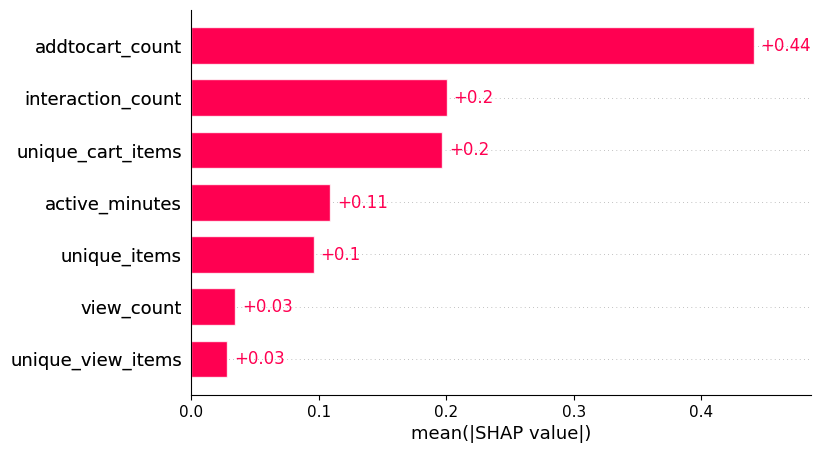

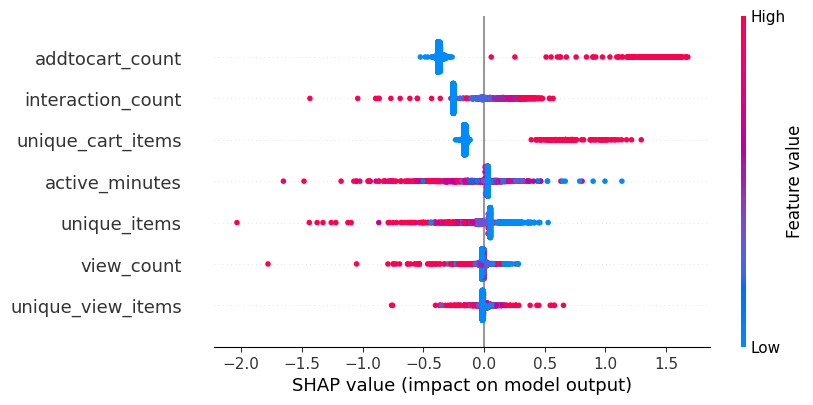


===== XẾP HẠNG ĐẶC TRƯNG THEO SHAP =====


,Feature,Mean_Abs_SHAP
2,addtocart_count,0.441349
0,interaction_count,0.200337
5,unique_cart_items,0.196834
6,active_minutes,0.109016
3,unique_items,0.096044
1,view_count,0.034328
4,unique_view_items,0.028211


In [ ]:
# Cài SHAP nếu môi trường chưa có
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "shap"
    ])

import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Lấy mẫu từ tập kiểm tra để phân tích
X_shap = X_test.sample(
    n=min(3000, len(X_test)),
    random_state=42
)

# Tạo bộ giải thích cho XGBoost
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_shap)

# 1. Biểu đồ mức độ quan trọng trung bình của các đặc trưng
shap.plots.bar(shap_values, max_display=10)

# 2. Biểu đồ SHAP thể hiện chiều tác động của đặc trưng
shap.plots.beeswarm(shap_values, max_display=10)

# 3. Bảng xếp hạng độ quan trọng theo mean absolute SHAP
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Abs_SHAP": np.abs(shap_values.values).mean(axis=0)
}).sort_values("Mean_Abs_SHAP", ascending=False)

print("\n===== XẾP HẠNG ĐẶC TRƯNG THEO SHAP =====")
display(shap_importance)

In [44]:
print("lr_model:", "lr_model" in globals())
print("lr_pipeline:", "lr_pipeline" in globals())
print("lgbm_model:", "lgbm_model" in globals())
print("xgb_model:", "xgb_model" in globals())

lr_model: True
lr_pipeline: False
lgbm_model: True
xgb_model: True


In [45]:

import pandas as pd
from google.colab import files

# ==========================================
# FILE 1: KẾT QUẢ DỰ ĐOÁN CỦA 3 MÔ HÌNH
# ==========================================

predictions = X_test.copy()

# Nhãn thực tế
predictions["actual_purchase"] = y_test.values

# Logistic Regression
predictions["lr_prediction"] = lr_model.predict(X_test)
predictions["lr_probability"] = lr_model.predict_proba(X_test)[:, 1]

# LightGBM
predictions["lgbm_prediction"] = lgbm_model.predict(X_test)
predictions["lgbm_probability"] = lgbm_model.predict_proba(X_test)[:, 1]

# XGBoost
predictions["xgb_prediction"] = xgb_model.predict(X_test)
predictions["xgb_probability"] = xgb_model.predict_proba(X_test)[:, 1]

predictions.to_csv(
    "/content/ml2_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

# ==========================================
# FILE 2: SO SÁNH CHỈ SỐ 3 MÔ HÌNH
# ==========================================

metrics_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.9250,
        "Precision": 0.4240,
        "Recall": 0.4631,
        "F1-score": 0.4427,
        "ROC-AUC": 0.7250,
        "PR-AUC": 0.2515
    },
    {
        "Model": "LightGBM",
        "Accuracy": 0.9094,
        "Precision": 0.3509,
        "Recall": 0.4802,
        "F1-score": 0.4055,
        "ROC-AUC": 0.7314,
        "PR-AUC": 0.3055
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.9047,
        "Precision": 0.3337,
        "Recall": 0.4829,
        "F1-score": 0.3947,
        "ROC-AUC": 0.7291,
        "PR-AUC": 0.3119
    }
])

metrics_df.to_csv(
    "/content/ml2_model_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

# ==========================================
# FILE 3: MỨC ĐỘ QUAN TRỌNG SHAP
# ==========================================

shap_importance.to_csv(
    "/content/ml2_shap_importance.csv",
    index=False,
    encoding="utf-8-sig"
)

# ==========================================
# KIỂM TRA CÁC FILE ĐÃ TẠO
# ==========================================

import os

for filename in [
    "ml2_predictions.csv",
    "ml2_model_metrics.csv",
    "ml2_shap_importance.csv"
]:
    path = "/content/" + filename
    print(filename, "—", os.path.getsize(path), "bytes")


ml2_predictions.csv — 2433841 bytes
ml2_model_metrics.csv — 219 bytes
ml2_shap_importance.csv — 211 bytes


In [46]:

from google.colab import files

files.download("/content/ml2_predictions.csv")
files.download("/content/ml2_model_metrics.csv")
files.download("/content/ml2_shap_importance.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>